In [1]:
# Start your code here!
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [2]:
# Load the women's dataset
women = pd.read_csv("/content/women_results.csv")

# Load the men's dataset
men = pd.read_csv("/content/men_results.csv")

In [3]:
men.head(5)

,Unnamed: 0,date,home_team,away_team,home_score,away_score,tournament
0,0,1872-11-30,Scotland,England,0,0,Friendly
1,1,1873-03-08,England,Scotland,4,2,Friendly
2,2,1874-03-07,Scotland,England,2,1,Friendly
3,3,1875-03-06,England,Scotland,2,2,Friendly
4,4,1876-03-04,Scotland,England,3,0,Friendly


In [4]:
men.info()

<class 'pandas.DataFrame'>
RangeIndex: 44353 entries, 0 to 44352
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  44353 non-null  int64
 1   date        44353 non-null  str  
 2   home_team   44353 non-null  str  
 3   away_team   44353 non-null  str  
 4   home_score  44353 non-null  int64
 5   away_score  44353 non-null  int64
 6   tournament  44353 non-null  str  
dtypes: int64(3), str(4)
memory usage: 4.2 MB


In [5]:
women.head(5)

,Unnamed: 0,date,home_team,away_team,home_score,away_score,tournament
0,0,1969-11-01,Italy,France,1,0,Euro
1,1,1969-11-01,Denmark,England,4,3,Euro
2,2,1969-11-02,England,France,2,0,Euro
3,3,1969-11-02,Italy,Denmark,3,1,Euro
4,4,1975-08-25,Thailand,Australia,3,2,AFC Championship


In [6]:
women.info()

<class 'pandas.DataFrame'>
RangeIndex: 4884 entries, 0 to 4883
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  4884 non-null   int64
 1   date        4884 non-null   str  
 2   home_team   4884 non-null   str  
 3   away_team   4884 non-null   str  
 4   home_score  4884 non-null   int64
 5   away_score  4884 non-null   int64
 6   tournament  4884 non-null   str  
dtypes: int64(3), str(4)
memory usage: 484.6 KB


In [7]:
# Convert women's date column to datetime
women["date"] = pd.to_datetime(women["date"])

# Convert men's date column to datetime
men["date"] = pd.to_datetime(men["date"])

In [8]:
women = women[
    (women["date"] >= "2002-01-01") &
    (women["tournament"] == "FIFA World Cup")
]

In [9]:
men = men[
    (men["date"] >= "2002-01-01") &
    (men["tournament"] == "FIFA World Cup")
]

In [10]:
print(women.shape)
print(men.shape)

(200, 7)
(384, 7)


In [11]:
print(women["tournament"].unique())
print(men["tournament"].unique())

<ArrowStringArray>
['FIFA World Cup']
Length: 1, dtype: str
<ArrowStringArray>
['FIFA World Cup']
Length: 1, dtype: str


In [12]:
women["goals_scored"] = (
    women["home_score"] + women["away_score"]
)
men["goals_scored"] = (
    men["home_score"] + men["away_score"]
)

In [13]:
women[["home_score", "away_score", "goals_scored"]].head()

,home_score,away_score,goals_scored
1600,0,3,3
1601,2,0,2
1602,4,1,5
1603,6,0,6
1604,3,1,4


In [14]:
men[["home_score", "away_score", "goals_scored"]].head()

,home_score,away_score,goals_scored
25164,0,1,1
25165,8,0,8
25166,1,1,2
25167,1,2,3
25168,1,0,1


In [15]:
# Count the number of women's matches
n_women = len(women)

# Count the number of men's matches
n_men = len(men)

print("Women's sample size:", n_women)
print("Men's sample size:", n_men)

Women's sample size: 200
Men's sample size: 384


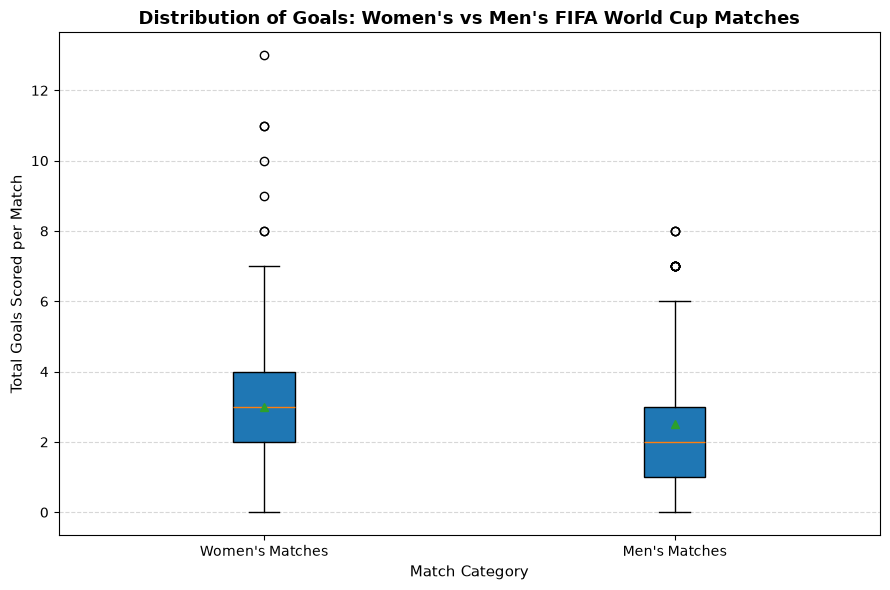

In [16]:
plt.figure(figsize=(9, 6))

# Prepare the data for the box plot
data = [
    women["goals_scored"].dropna(),
    men["goals_scored"].dropna()
]

# Create the box plot
plt.boxplot(
    data,
    tick_labels=["Women's Matches", "Men's Matches"],
    patch_artist=True,
    showmeans=True
)

# Add chart title and labels
plt.title(
    "Distribution of Goals: Women's vs Men's FIFA World Cup Matches",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Match Category", fontsize=11)
plt.ylabel("Total Goals Scored per Match", fontsize=11)

# Add gridlines
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Display chart
plt.tight_layout()
plt.savefig(
    "football_goals_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

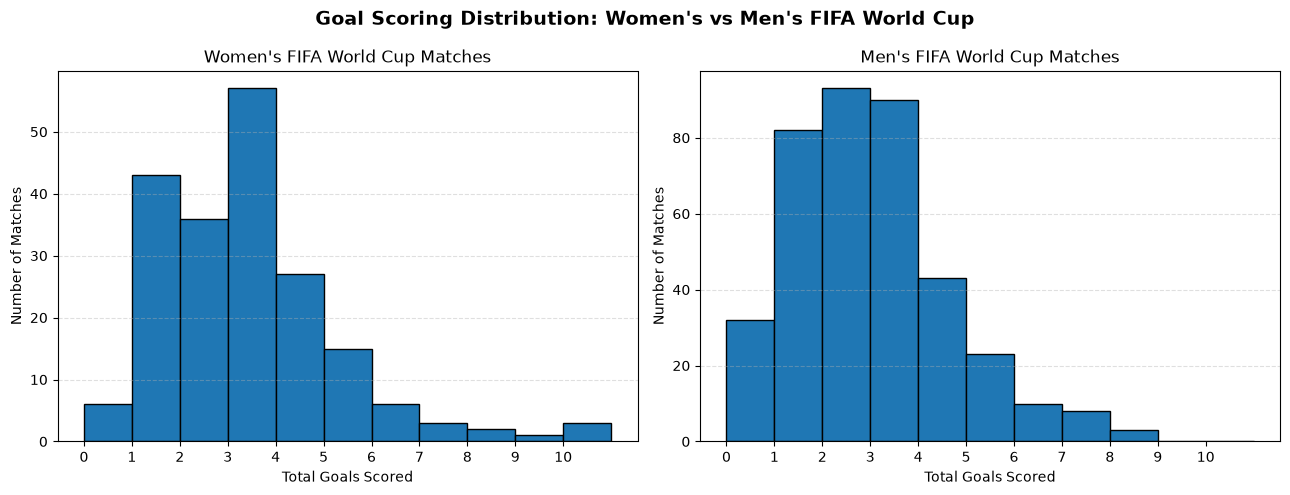

In [17]:
import matplotlib.pyplot as plt

# Create two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Women's matches histogram
axes[0].hist(
    women["goals_scored"].dropna(),
    bins=range(0, 12),
    edgecolor="black"
)

axes[0].set_title("Women's FIFA World Cup Matches")
axes[0].set_xlabel("Total Goals Scored")
axes[0].set_ylabel("Number of Matches")
axes[0].set_xticks(range(0, 11))
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

# Men's matches histogram
axes[1].hist(
    men["goals_scored"].dropna(),
    bins=range(0, 12),
    edgecolor="black"
)

axes[1].set_title("Men's FIFA World Cup Matches")
axes[1].set_xlabel("Total Goals Scored")
axes[1].set_ylabel("Number of Matches")
axes[1].set_xticks(range(0, 11))
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

# Overall chart title
fig.suptitle(
    "Goal Scoring Distribution: Women's vs Men's FIFA World Cup",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    "football_goals_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

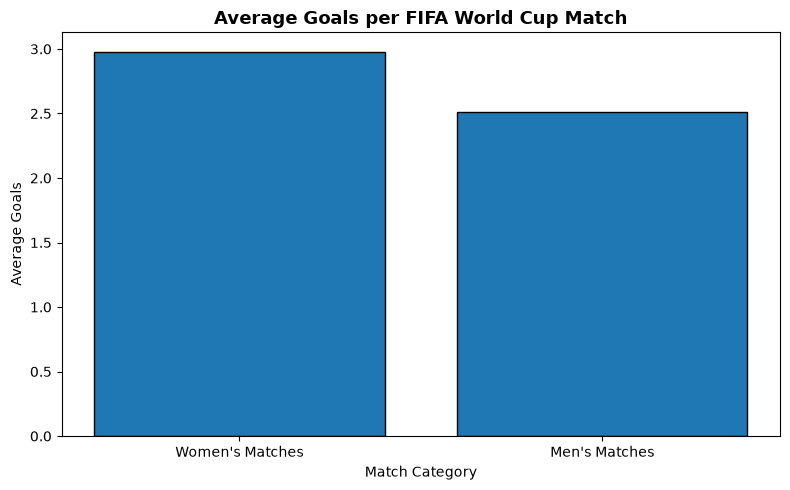

In [18]:
# Calculate average goals
average_goals = [
    women["goals_scored"].mean(),
    men["goals_scored"].mean()
]

# Create bar chart
plt.figure(figsize=(8, 5))

plt.bar(
    ["Women's Matches", "Men's Matches"],
    average_goals,
    edgecolor="black"
)

plt.title(
    "Average Goals per FIFA World Cup Match",
    fontsize=13,
    fontweight="bold"
)

plt.ylabel("Average Goals")
plt.xlabel("Match Category")

plt.tight_layout()
plt.savefig(
    "football_goals_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [19]:
# Shapiro-Wilk test for women's goals
women_shapiro = stats.shapiro(women["goals_scored"])

# Shapiro-Wilk test for men's goals
men_shapiro = stats.shapiro(men["goals_scored"])

print("Women's p-value:", women_shapiro.pvalue)
print("Men's p-value:", men_shapiro.pvalue)

Women's p-value: 3.890829384462926e-13
Men's p-value: 8.894989197030093e-13


In [20]:
women_goals = women[["goals_scored"]].copy()
women_goals["gender"] = "women"

men_goals = men[["goals_scored"]].copy()
men_goals["gender"] = "men"

both = pd.concat(
    [women_goals, men_goals],
    ignore_index=True
)


In [21]:
both_wide = both.pivot(
    columns="gender",
    values="goals_scored"
)

print(both_wide.head())


gender  men  women
0       NaN    3.0
1       NaN    2.0
2       NaN    5.0
3       NaN    6.0
4       NaN    4.0


In [22]:
!pip install pingouin

In [23]:
import pingouin as pg
mwu_result = pg.mwu(
    x=both_wide["women"],
    y=both_wide["men"],
    alternative="greater"
)

print(mwu_result)

       U_val alternative     p_val       RBC      CLES
MWU  43273.0     greater  0.005107  0.126901  0.563451


In [25]:
p_val = mwu_result["p_val"].to_numpy()[0]

print("P-value:", p_val)


P-value: 0.005106609825443641


In [26]:
mwu_scipy = stats.mannwhitneyu(
    x=women["goals_scored"],
    y=men["goals_scored"],
    alternative="greater"
)

scipy_p_val = mwu_scipy.pvalue

print("SciPy p-value:", scipy_p_val)

SciPy p-value: 0.005106609825443641


In [27]:
alpha = 0.10

if p_val < alpha:
    result = "reject"
else:
    result = "fail to reject"


In [28]:
result_dict = {
    "p_val": p_val,
    "result": result
}

print(result_dict)

{'p_val': np.float64(0.005106609825443641), 'result': 'reject'}
